In [168]:
import numpy as np
import matplotlib.pyplot as plt


In [169]:
rng = np.random.default_rng(seed=42)
size= 100
lr= 0.01
tao= 0.5
epochs= 100

In [170]:
x= rng.integers(low=0, high=10, size=(size))
y= rng.integers(low=0, high=2, size=(size))
weight= np.random.rand(1) #number of weights= number of features. That weight is multiplied to all the inputs. 
bias= 0

In [171]:
def sigmoid(z):
        z = np.clip(np.asarray(z), 1e-15, 1 - 1e-15)
        arr= (1/(1+np.exp(-1*z)))
        return arr

In [172]:
class model:
    def __init__(self, lr, tao):
        self.lr= lr
        self.tao =tao
        
    def prediction(self, weight, bias, x):
        pred= weight * x + bias
        probs= sigmoid(pred)
        return probs, (probs>self.tao).astype(int)
    
    def my_loss(self, y_pred, y_act):
        tot_los=-( y_act * np.log(y_pred)+(1-y_act) * np.log(1-y_pred)) #bce loss is good because it penalises more if the deviation is more (look at the graph)
        return np.mean(tot_los)
    def train(self, w, b, rng, y_act, x, size):
        loss_history= []
        lr= self.lr
        for i in range(rng):
            probs, _ = self.prediction(w, b, x)
            delW= -x*(y_act- probs)
            delB= -(y_act- probs)
            delW= np.sum(delW)/size
            # print("delw is ", delW)
            # print("delb is ", delB)
            delB= np.sum(delB)/size
            w= w- lr*delW
            print("weight is ", w)
            b= b- lr*delB
            print("bias is ", b)
            loss_history.append(self.my_loss(probs, y_act))
        return w, b, loss_history


weight is  [0.76446934]
bias is  -0.0021607257847474164
weight is  [0.75443455]
bias is  -0.00431907540318578
weight is  [0.74440215]
bias is  -0.00647503922209707
weight is  [0.73437214]
bias is  -0.008628607732327195
weight is  [0.72434454]
bias is  -0.010779771551047918
weight is  [0.71431935]
bias is  -0.012928521423996435
weight is  [0.70429659]
bias is  -0.0150748482276915
weight is  [0.69427626]
bias is  -0.017218742971624925
weight is  [0.68425837]
bias is  -0.019360196800427373
weight is  [0.67424292]
bias is  -0.021499200996007266
weight is  [0.66422994]
bias is  -0.02363574697966174
weight is  [0.65421942]
bias is  -0.025769826314158546
weight is  [0.64421138]
bias is  -0.027901430705787753
weight is  [0.63420582]
bias is  -0.03003055200638225
weight is  [0.62420275]
bias is  -0.03215718221530592
weight is  [0.61420218]
bias is  -0.034281313481408456
weight is  [0.60420412]
bias is  -0.03640293810494578
weight is  [0.59420857]
bias is  -0.03852204853946504
weight is  [0.5842

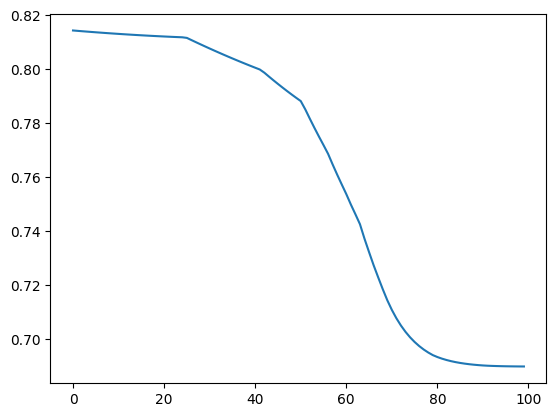

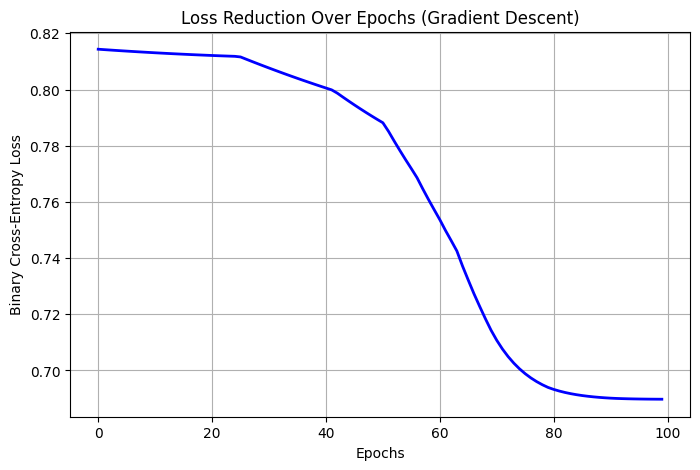

In [173]:
my_model= model(lr, tao)
probs ,y_pred= my_model.prediction(weight, bias, x)
# print(sigmoid(1), sigmoid(10), sigmoid(-10))
# print(x)
# print(y)
# print(y_pred)
# print(probs)
# print("weight is", weight)
loss= my_model.my_loss(probs, y)
# print("loss", loss)
weight, bias, loss_hist= my_model.train(weight, bias, epochs, y, x, size)
print("w and b", weight, bias)
print(loss_hist)
plt.plot(range(epochs), loss_hist)
plt.show


plt.figure(figsize=(8, 5))
plt.plot(range(epochs), loss_hist, color='blue', linewidth=2)
plt.title('Loss Reduction Over Epochs (Gradient Descent)')
plt.xlabel('Epochs')
plt.ylabel('Binary Cross-Entropy Loss')
plt.grid(True)
plt.show()

#doubts: is loss too much? why are we dividing by m? 
